In [12]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [75]:
IMAGE_DIR = "/tmp/bshi/plantnet/"
META_DIR = "../data/plantnet/"

In [76]:
species_metadata = pd.read_csv(IMAGE_DIR + "species_metadata.csv")
species_metadata["genus_id"] = pd.factorize(species_metadata['genus'])[0]
species_metadata.to_csv(IMAGE_DIR + "species_genus_metadata.csv")
geo = pd.read_csv(META_DIR + "plantnet_geo.csv")
merged = geo.merge(species_metadata, on="species_id", how="left", validate="many_to_one")

In [77]:
species_sizes = merged.groupby(["species_id"]).size()
genus_sizes = merged.groupby(["genus_id"]).size()
species_per_genus = merged.groupby(["genus_id"])["species_id"].nunique()

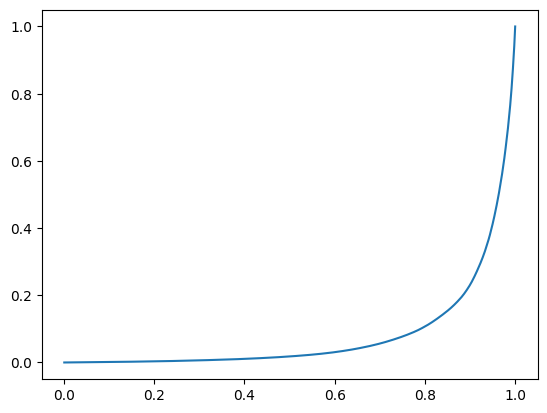

In [78]:
sorted_species_sizes = species_sizes.sort_values(ascending=True)
total = sum(species_sizes)
xs = np.array(range(len(species_sizes))) + 1
ys = []
count = 0
for i in range(len(species_sizes)):
    count += sorted_species_sizes.iloc[i]
    ys.append(count)
xs = xs / len(species_sizes)
ys = np.array(ys) / total
plt.plot(xs, ys)

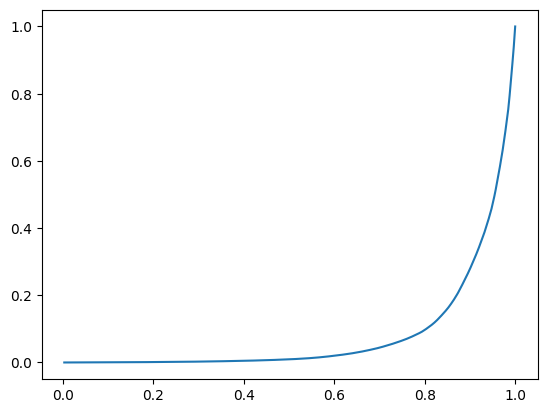

In [79]:
sorted_genus_sizes = genus_sizes.sort_values(ascending=True)
total = sum(genus_sizes)
xs = np.array(range(len(genus_sizes))) + 1
ys = []
count = 0
for i in range(len(genus_sizes)):
    count += sorted_genus_sizes.iloc[i]
    ys.append(count)
xs = xs / len(genus_sizes)
ys = np.array(ys) / total
plt.plot(xs, ys)

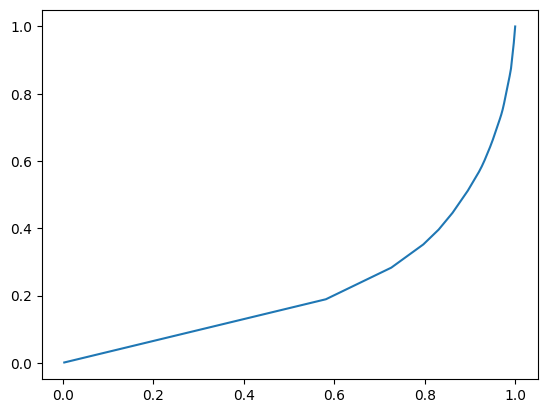

In [80]:
sorted_species_per_genus = species_per_genus.sort_values(ascending=True)
total = sum(species_per_genus)
xs = np.array(range(len(species_per_genus))) + 1
ys = []
count = 0
for i in range(len(species_per_genus)):
    count += sorted_species_per_genus.iloc[i]
    ys.append(count)
xs = xs / len(species_per_genus)
ys = np.array(ys) / total
plt.plot(xs, ys)

In [81]:
total = sum(merged.groupby(["split"]).size())
merged.groupby(["split"]).size() / total

split
test     0.101625
train    0.796721
val      0.101654
dtype: float64

In [82]:
def split_keep_singletons(idx, y, test_ratio, seed=0):
    """Stratified split; labels with a single sample always go to the first (train) set."""
    idx, y = np.asarray(idx), np.asarray(y)
    ok = pd.Series(y).map(pd.Series(y).value_counts()).to_numpy() >= 2   # label has >= 2 samples
    n_test = int(np.ceil(test_ratio * len(idx)))     # integer count so the total stays exact
    tr, te = train_test_split(idx[ok], test_size=n_test, random_state=seed, stratify=y[ok])
    return np.concatenate([tr, idx[~ok]]), te

### Predict genus, but remove certain species from genus

In [ ]:
test_ratio = 0.1

seed = 0
rng = np.random.default_rng(seed)

sp_counts = (
    merged.groupby(["genus_id", "species_id"]).size()
    .rename("n_images").reset_index()
    .sort_values(["genus_id", "n_images", "species_id"])   # smallest species first; species_id breaks ties
)
sp_counts["genus_total"] = sp_counts.groupby("genus_id")["n_images"].transform("sum")
sp_counts["cum_images"] = sp_counts.groupby("genus_id")["n_images"].cumsum()
sp_counts["is_test"] = sp_counts["cum_images"] <= test_ratio * sp_counts["genus_total"]
test_species = set(sp_counts.loc[sp_counts["is_test"], "species_id"])
merged["genus_split"] = np.where(merged["species_id"].isin(test_species), "test", "train")

for g, gdf in merged.groupby("genus_id"):
    need = int(np.ceil(test_ratio * len(gdf))) - (gdf["genus_split"] == "test").sum()
    if need <= 0:
        continue
    remaining = sp_counts[(sp_counts["genus_id"] == g) & ~sp_counts["is_test"]]   # already smallest first
    for sid, n in zip(remaining["species_id"], remaining["n_images"]):
        if need <= 0:
            break
        idx = gdf.index[gdf["species_id"] == sid]
        chosen = rng.choice(idx, size=min(need, n), replace=False)
        merged.loc[chosen, "genus_split"] = "test"
        need -= len(chosen)


total = sum(merged.groupby(["genus_split"]).size())
train_pos = np.flatnonzero(merged["genus_split"] == "train")
val_ratio = 0.1 / (merged.groupby(["genus_split"]).size() / total)["train"]
val_inds = train_test_split(train_pos, test_size=val_ratio, random_state=seed, stratify=merged["genus_id"][train_pos])[1]
merged.loc[val_inds, "genus_split"] = "val"

In [85]:
total = sum(merged.groupby(["genus_split"]).size())
merged.groupby(["genus_split"]).size() / total

genus_split
test     0.100485
train    0.799515
val      0.100001
dtype: float64

### Use geolocation data

In [86]:
has_geo = merged["lat"].notna() & merged["lon"].notna()
pts = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(merged.loc[has_geo, "lon"], merged.loc[has_geo, "lat"]),
    index=merged.index[has_geo],
    crs="EPSG:4326",
)

world = gpd.read_file(
    "https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_countries.zip"
)[["ADMIN", "geometry"]]

j = gpd.sjoin(pts, world, how="left", predicate="within")
j = j[~j.index.duplicated(keep="first")]        # a point on a border can match two polygons
                 # aligned on index; stays NaN where lat/lon is missing
merged["country"] = j["ADMIN"]

In [87]:
test_ratio = 0.1
seed = 0

merged_w_countries = merged[merged["country"].notna()]
test_num = test_ratio * len(merged_w_countries)   
total = merged_w_countries.groupby("species_id").size()  
ct = pd.crosstab(merged_w_countries["species_id"], merged_w_countries["country"]) 
test_cnt = pd.Series(0, index=total.index)

chosen, used = [], 0
for c in ct.sum().sort_values().index:          # countries by image count, smallest first
    n = int(ct[c].sum())
    if used + n > test_num:
        break                                   # later countries are bigger, so they won't fit either
    new = test_cnt + ct[c]
    if (new >= total).any():                    # would leave some species with no train image
        continue
    test_cnt, used = new, used + n
    chosen.append(c)


rng = np.random.default_rng(seed)
need = int(np.ceil(test_ratio * len(merged_w_countries))) - used            # test images still missing

trainpool = merged_w_countries[~merged_w_countries["country"].isin(chosen)]        # located images not in a test country
reserved = trainpool.groupby("species_id").sample(1, random_state=0)   # 1 image per species stays in train
pool = trainpool.drop(reserved.index)

extra = []
for c in trainpool.groupby("country").size().sort_values().index:      # smallest remaining countries first
    if need <= 0:
        break
    idx = pool.index[pool["country"] == c]
    take = rng.choice(idx, size=min(need, len(idx)), replace=False)
    extra.extend(take)
    need -= len(take)
assert need <= 0, "not enough images to reach the test quota"

merged["country_split"] = np.nan
merged.loc[merged_w_countries.index, "country_split"] = "train"
merged.loc[merged_w_countries.index[merged_w_countries["country"].isin(chosen)], "country_split"] = "test"
merged.loc[extra, "country_split"] = "test"

total = sum(merged.groupby(["country_split"]).size())
train_pos = np.flatnonzero(merged["country_split"] == "train")
val_ratio = 0.1 / (merged.groupby(["country_split"]).size() / total)["train"]
val_inds = split_keep_singletons(train_pos, merged["species_id"][train_pos], test_ratio=val_ratio, seed=seed)[1]
merged.loc[val_inds, "country_split"] = "val"

/tmp/ipykernel_116384/1205367787.py:40: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'train' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  merged.loc[merged_w_countries.index, "country_split"] = "train"


In [88]:
merged[merged["country"].notna()].groupby(["country_split"]).size() / sum(merged[merged["country"].notna()].groupby(["country_split"]).size())

country_split
test     0.100005
train    0.799990
val      0.100005
dtype: float64

In [92]:
merged = merged[["PN_hash", "PN_observation_id", "species_id", "species", "genus_id", "genus", "country", "split", "genus_split", "country_split"]]
merged = merged.rename(columns={"split": "original_split"})


merged.to_csv(META_DIR + "plantnet_geo_final.csv")